# Task 02 – Build and Compare Machine Learning Models

**Organization:** Devixo Solutions  
**Project:** Customer Churn Prediction  
**Technology:** Python, Pandas, NumPy, Scikit-learn, Matplotlib, Seaborn

## Objective

The objective of this project is to develop and compare multiple machine learning classification models to predict customer churn. The project focuses on data preprocessing, feature engineering, model development, performance evaluation, and model selection.


In [1]:

# Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings

# Machine Learning Libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Ignore unnecessary warnings
warnings.filterwarnings('ignore')

# Visualization Settings
sns.set_style('whitegrid')

print("All libraries imported successfully!")


All libraries imported successfully!


## Part 1 – Data Preprocessing

### 1.1 Loading the Dataset

In this section, the customer churn dataset is loaded into a Pandas DataFrame for initial inspection and preprocessing.


In [2]:

from google.colab import files

uploaded = files.upload()


Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv


In [3]:

import io

file_name = list(uploaded.keys())[0]

df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 1.2 Understanding the Dataset

The dataset contains 7,043 customer records and 21 columns. In this step, we will examine the dataset structure, data types, and non-null values to understand the data before preprocessing.

In [4]:

# Display dataset information

print("Dataset Information:")
df.info()

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nStatistical Summary:")
display(df.describe(include='all'))


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


### 1.3 Handling Missing Values

Missing values are identified in each column to ensure data quality. We will examine the number and percentage of missing values before deciding how to handle them.

In [5]:

# Check missing values

missing_values = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage': (df.isnull().sum() / len(df)) * 100
})

missing_values = missing_values[missing_values['Missing Values'] > 0]

print("Missing Values Analysis:")
display(missing_values)


Missing Values Analysis:


,Missing Values,Percentage


### 1.4 Removing Duplicate Records

Duplicate records are identified to prevent repeated observations from affecting model training. Any duplicate rows will be removed.

In [6]:

# Check duplicate records

duplicate_count = df.duplicated().sum()

print("Number of Duplicate Rows:", duplicate_count)

# Remove duplicate records

df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)


Number of Duplicate Rows: 0
Dataset Shape After Removing Duplicates: (7043, 21)


### 1.5 Data Type Conversion

The `TotalCharges` column contains numerical values stored as an object data type. Blank or whitespace entries are converted into missing values, and the column is transformed into a numerical format.

In [7]:

# Convert TotalCharges to numeric

df['TotalCharges'] = df['TotalCharges'].astype(str).str.strip()

df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

print("TotalCharges Data Type:", df['TotalCharges'].dtype)
print("Missing Values in TotalCharges:", df['TotalCharges'].isnull().sum())

# Display rows with missing TotalCharges
display(df[df['TotalCharges'].isnull()])


TotalCharges Data Type: float64
Missing Values in TotalCharges: 11


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


### 1.6 Target Variable Distribution

The target variable `Churn` is examined to understand the distribution of customers who have left the service and those who have continued using it.

Churn Distribution:


,count
Churn,
No,5174
Yes,1869



Churn Percentage:


,proportion
Churn,
No,73.463013
Yes,26.536987


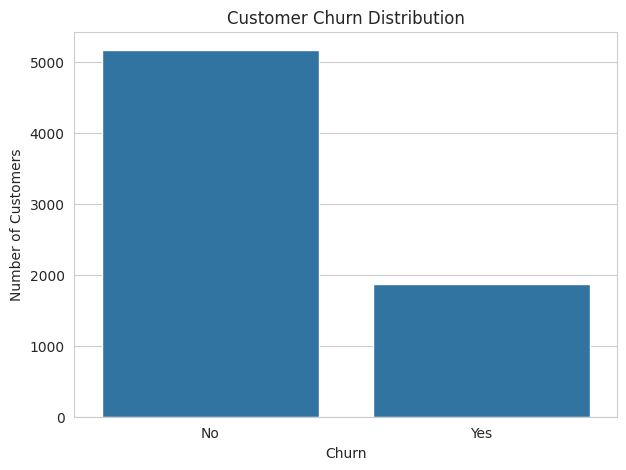

In [8]:

# Check target variable distribution

print("Churn Distribution:")
display(df['Churn'].value_counts())

print("\nChurn Percentage:")
display(df['Churn'].value_counts(normalize=True) * 100)

# Visualize churn distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Churn')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')

plt.show()


### 1.7 Handling Missing Values

The `TotalCharges` column contains 11 missing values. After investigation, all 11 records were found to have zero customer tenure. Therefore, these missing values are replaced with zero because customers with zero tenure have no accumulated total charges.

In [9]:

# Fill missing TotalCharges with 0

df['TotalCharges'] = df['TotalCharges'].fillna(0)

# Verify missing values
print("Missing Values After Treatment:")
print(df.isnull().sum().sum())

print("\nMissing Values in TotalCharges:")
print(df['TotalCharges'].isnull().sum())

print("\nUpdated Dataset Shape:", df.shape)


Missing Values After Treatment:
0

Missing Values in TotalCharges:
0

Updated Dataset Shape: (7043, 21)


### 1.8 Final Data Quality Check

After handling missing values, the dataset is checked again to ensure that it is clean and ready for further preprocessing.

In [10]:

print("Final Dataset Information:")
print("Dataset Shape:", df.shape)
print("Total Missing Values:", df.isnull().sum().sum())
print("Total Duplicate Rows:", df.duplicated().sum())

print("\nUpdated Data Types:")
display(df.dtypes)


Final Dataset Information:
Dataset Shape: (7043, 21)
Total Missing Values: 0
Total Duplicate Rows: 0

Updated Data Types:


,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


### 1.9 Removing Unnecessary Features

The `customerID` column is removed because it is a unique identifier and does not provide meaningful information for predicting customer churn.

In [11]:

# Remove customerID column

df = df.drop('customerID', axis=1)

print("Dataset Shape After Removing customerID:", df.shape)

print("\nRemaining Columns:")
print(df.columns.tolist())


Dataset Shape After Removing customerID: (7043, 20)

Remaining Columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


### 1.10 Separating Features and Target Variable

The dataset is divided into independent features (X) and the target variable (y). The target variable `Churn` is converted into numerical values, where No = 0 and Yes = 1.

In [12]:

# Separate features and target

X = df.drop('Churn', axis=1)

y = df['Churn'].map({'No': 0, 'Yes': 1})

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Variable Distribution:")
print(y.value_counts())


Features Shape: (7043, 19)
Target Shape: (7043,)

Target Variable Distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


### 1.11 Splitting the Dataset

The dataset is divided into training and testing sets using an 80:20 ratio. Stratified sampling is applied to maintain the original class distribution in both sets.

In [13]:

# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)


Training Features: (5634, 19)
Testing Features: (1409, 19)
Training Target: (5634,)
Testing Target: (1409,)


### 1.12 Encoding Categorical Features and Scaling Numerical Features

Categorical features are transformed using One-Hot Encoding, while numerical features are standardized using StandardScaler. The preprocessing transformations are fitted on the training data and applied to the testing data.

In [14]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify numerical and categorical columns

numerical_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical Features:", numerical_features)
print("\nCategorical Features:", categorical_features)

# Create preprocessing transformer

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# Fit on training data and transform both datasets

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("\nPreprocessing Completed Successfully!")
print("Processed Training Shape:", X_train_processed.shape)
print("Processed Testing Shape:", X_test_processed.shape)


Numerical Features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Preprocessing Completed Successfully!
Processed Training Shape: (5634, 45)
Processed Testing Shape: (1409, 45)


# Part 2 – Model Development

In this section, three different machine learning classification algorithms are trained using the preprocessed customer churn dataset.

The selected algorithms are:

1. Logistic Regression
2. Decision Tree Classifier
3. Random Forest Classifier

Each model is trained using the same training dataset to ensure a fair performance comparison.

In [15]:

# Import required models and time module

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import time

# Initialize the models

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),

    'Decision Tree': DecisionTreeClassifier(random_state=42),

    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

# Train all models and calculate training time

trained_models = {}
training_times = {}

for name, model in models.items():

    start_time = time.perf_counter()

    model.fit(X_train_processed, y_train)

    end_time = time.perf_counter()

    training_time = end_time - start_time

    trained_models[name] = model
    training_times[name] = training_time

    print(f"{name} trained successfully!")
    print(f"Training Time: {training_time:.4f} seconds")
    print("-" * 40)

print("\nAll three models trained successfully!")


Logistic Regression trained successfully!
Training Time: 0.0607 seconds
----------------------------------------
Decision Tree trained successfully!
Training Time: 0.0696 seconds
----------------------------------------
Random Forest trained successfully!
Training Time: 0.8597 seconds
----------------------------------------

All three models trained successfully!


### 2.1 Model Training Summary

All three selected machine learning models have been successfully trained using the preprocessed training dataset. Their training times are recorded for comparison in the evaluation stage.

In [16]:

# Display model training times

training_summary = pd.DataFrame({
    'Model Name': list(training_times.keys()),
    'Training Time (Seconds)': list(training_times.values())
})

display(training_summary)


,Model Name,Training Time (Seconds)
0,Logistic Regression,0.060695
1,Decision Tree,0.069636
2,Random Forest,0.859715


# Part 3 – Model Evaluation

In this section, the trained machine learning models are evaluated using the testing dataset. Accuracy, Precision, Recall, and F1 Score are calculated to assess model performance. Confusion matrices are also generated to examine the classification results.

In [17]:

# Generate predictions using all trained models

predictions = {}

for name, model in trained_models.items():

    y_pred = model.predict(X_test_processed)

    predictions[name] = y_pred

    print(f"{name} predictions generated successfully!")

print("\nAll predictions generated successfully!")


Logistic Regression predictions generated successfully!
Decision Tree predictions generated successfully!
Random Forest predictions generated successfully!

All predictions generated successfully!


### 3.1 Performance Evaluation Metrics

The performance of each model is measured using Accuracy, Precision, Recall, and F1 Score. These metrics help evaluate how effectively each algorithm predicts customer churn.

In [18]:

# Calculate evaluation metrics for all models

evaluation_results = []

for name, y_pred in predictions.items():

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    evaluation_results.append({
        'Model Name': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    })

# Create evaluation comparison table

evaluation_df = pd.DataFrame(evaluation_results)

print("Model Evaluation Results:")
display(evaluation_df.round(4))


Model Evaluation Results:


,Model Name,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040
1,Decision Tree,0.7211,0.4755,0.4920,0.4836
2,Random Forest,0.7864,0.6254,0.4866,0.5474


### 3.2 Confusion Matrix Analysis

Confusion matrices are generated for all three models to visualize the number of correct and incorrect predictions. They show True Positives, True Negatives, False Positives, and False Negatives.

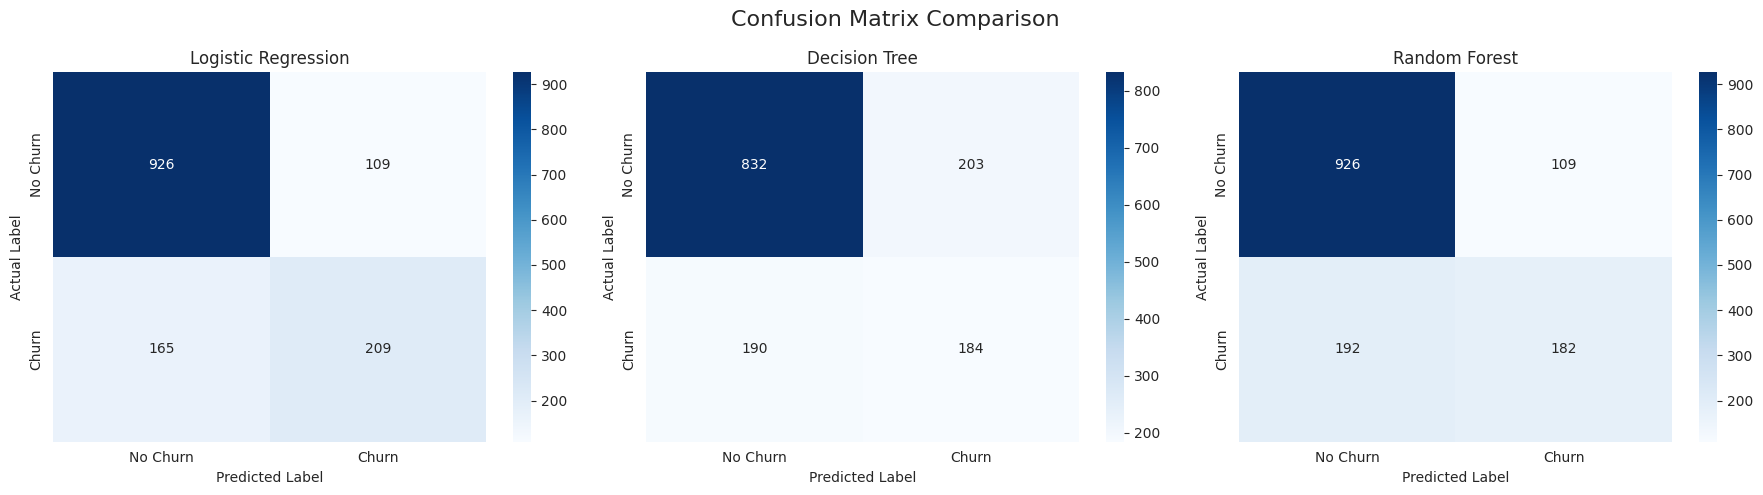

In [19]:

# Plot confusion matrices for all models

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax,
        xticklabels=['No Churn', 'Churn'],
        yticklabels=['No Churn', 'Churn']
    )

    ax.set_title(name)
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('Actual Label')

plt.suptitle('Confusion Matrix Comparison', fontsize=16)
plt.tight_layout()
plt.show()


### 3.3 Detailed Classification Reports

Classification reports are generated to provide detailed precision, recall, and F1 scores for each class, along with macro and weighted averages.

In [20]:

# Generate classification reports

for name, y_pred in predictions.items():

    print(f"\nClassification Report: {name}")
    print("=" * 55)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=['No Churn', 'Churn']
        )
    )



Classification Report: Logistic Regression
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409


Classification Report: Decision Tree
              precision    recall  f1-score   support

    No Churn       0.81      0.80      0.81      1035
       Churn       0.48      0.49      0.48       374

    accuracy                           0.72      1409
   macro avg       0.64      0.65      0.65      1409
weighted avg       0.72      0.72      0.72      1409


Classification Report: Random Forest
              precision    recall  f1-score   support

    No Churn       0.83      0.89      0.86      1035
       Churn       0.63      0.49      0.55       374

    accuracy                           0.79      1409
   macro

# Part 4 – Model Comparison

In this section, all three machine learning models are compared based on their training time, evaluation metrics, advantages, and limitations. This comparison helps identify the most suitable model for customer churn prediction.

In [21]:

# Create comprehensive model comparison table

advantages = {
    'Logistic Regression':
        'Fast training, simple and interpretable, best evaluation scores.',

    'Decision Tree':
        'Easy to understand and interpret, captures non-linear patterns.',

    'Random Forest':
        'Ensemble learning, reduces overfitting compared to a single tree.'
}

limitations = {
    'Logistic Regression':
        'Assumes a linear relationship between features and log-odds.',

    'Decision Tree':
        'Can overfit and may be sensitive to small data changes.',

    'Random Forest':
        'Higher training time and lower interpretability than a single tree.'
}

comparison_df = evaluation_df.copy()

comparison_df['Training Time (Seconds)'] = comparison_df[
    'Model Name'
].map(training_times)

comparison_df['Advantages'] = comparison_df[
    'Model Name'
].map(advantages)

comparison_df['Limitations'] = comparison_df[
    'Model Name'
].map(limitations)

# Arrange columns according to task requirements

comparison_df = comparison_df[
    [
        'Model Name',
        'Training Time (Seconds)',
        'Accuracy',
        'Precision',
        'Recall',
        'F1 Score',
        'Advantages',
        'Limitations'
    ]
]

print("Complete Model Comparison:")
display(comparison_df.round(4))


Complete Model Comparison:


,Model Name,Training Time (Seconds),Accuracy,Precision,Recall,F1 Score,Advantages,Limitations
0,Logistic Regression,0.0607,0.8055,0.6572,0.5588,0.6040,"Fast training, simple and interpretable, best ...",Assumes a linear relationship between features...
1,Decision Tree,0.0696,0.7211,0.4755,0.4920,0.4836,"Easy to understand and interpret, captures non...",Can overfit and may be sensitive to small data...
2,Random Forest,0.8597,0.7864,0.6254,0.4866,0.5474,"Ensemble learning, reduces overfitting compare...",Higher training time and lower interpretabilit...


### 4.1 Visual Comparison of Model Performance

A bar chart is created to compare the Accuracy, Precision, Recall, and F1 Score of all three machine learning models.

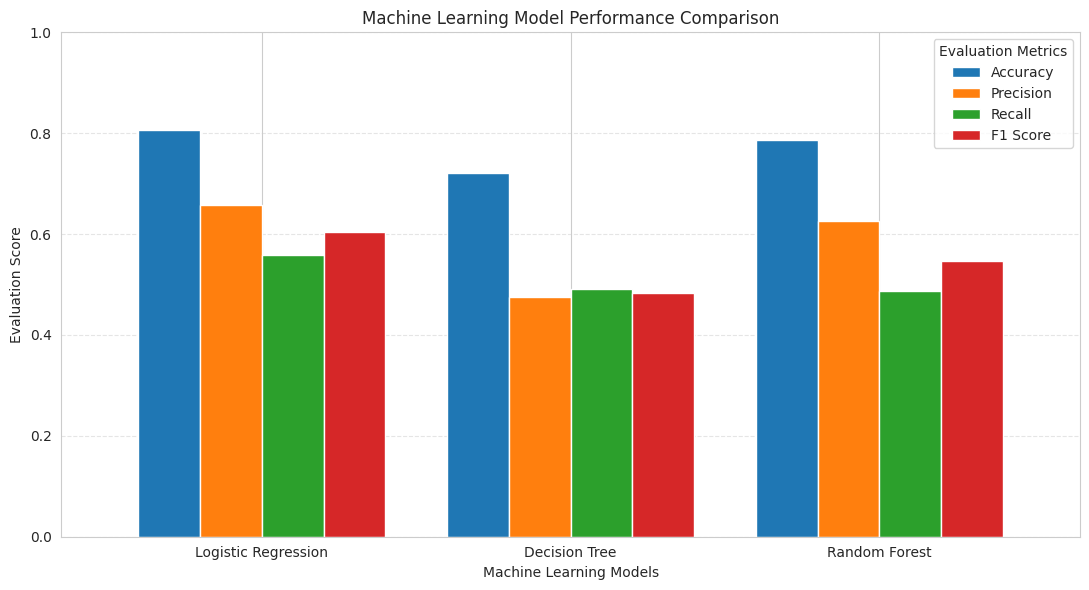

In [22]:

# Visualize model performance

metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']

comparison_df.set_index('Model Name')[metrics].plot(
    kind='bar',
    figsize=(11, 6),
    width=0.8
)

plt.title('Machine Learning Model Performance Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Evaluation Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title='Evaluation Metrics')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


# Part 5 – Conclusion

The customer churn prediction project successfully implemented and compared three machine learning classification algorithms: Logistic Regression, Decision Tree, and Random Forest.

Based on the initial evaluation results, Logistic Regression achieved the highest accuracy of 80.55%, precision of 65.72%, recall of 55.88%, and F1 Score of 60.40%.

Decision Tree achieved an accuracy of 72.11%, while Random Forest achieved 78.64%.

Logistic Regression demonstrated the strongest overall performance among the three initial models. However, further hyperparameter tuning can help investigate whether model performance can be improved.

This project provided practical experience in data preprocessing, feature encoding, feature scaling, model training, evaluation, and comparison.

# Bonus – Hyperparameter Tuning

Hyperparameter tuning is performed using GridSearchCV to find better model configurations. The process uses cross-validation to evaluate different parameter combinations and identify the best-performing settings.

In [23]:

from sklearn.model_selection import GridSearchCV

print("GridSearchCV imported successfully!")


GridSearchCV imported successfully!


### 5.1 Hyperparameter Tuning Using GridSearchCV

GridSearchCV is applied to Logistic Regression, Decision Tree, and Random Forest. Different hyperparameter combinations are tested using 3-fold cross-validation. The F1 Score is used as the optimization metric to balance precision and recall for customer churn prediction.

In [24]:

# Define hyperparameter grids

param_grids = {
    'Logistic Regression': {
        'C': [0.1, 1, 10],
        'class_weight': [None, 'balanced']
    },

    'Decision Tree': {
        'max_depth': [None, 10, 20],
        'min_samples_split': [2, 5],
        'class_weight': [None, 'balanced']
    },

    'Random Forest': {
        'n_estimators': [100, 200],
        'max_depth': [None, 10],
        'min_samples_split': [2, 5],
        'class_weight': [None, 'balanced']
    }
}

# Store tuned models and results

tuned_models = {}
tuning_results = {}

# Perform GridSearchCV

for name, model in models.items():

    print(f"\nTuning {name}...")

    start_time = time.perf_counter()

    grid_search = GridSearchCV(
        estimator=model,
        param_grid=param_grids[name],
        scoring='f1',
        cv=3,
        n_jobs=-1,
        verbose=0
    )

    grid_search.fit(X_train_processed, y_train)

    end_time = time.perf_counter()

    tuned_models[name] = grid_search.best_estimator_

    tuning_results[name] = {
        'Best Parameters': grid_search.best_params_,
        'Best CV F1 Score': grid_search.best_score_,
        'Tuning Time (Seconds)': end_time - start_time
    }

    print("Best Parameters:", grid_search.best_params_)
    print("Best CV F1 Score:", round(grid_search.best_score_, 4))
    print("Tuning Time:", round(end_time - start_time, 4), "seconds")

print("\nHyperparameter Tuning Completed!")



Tuning Logistic Regression...
Best Parameters: {'C': 0.1, 'class_weight': 'balanced'}
Best CV F1 Score: 0.6329
Tuning Time: 6.3697 seconds

Tuning Decision Tree...
Best Parameters: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_split': 5}
Best CV F1 Score: 0.5709
Tuning Time: 1.9032 seconds

Tuning Random Forest...
Best Parameters: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 100}
Best CV F1 Score: 0.6323
Tuning Time: 61.0459 seconds

Hyperparameter Tuning Completed!


### 5.2 Evaluation of Tuned Models

The best-performing configurations obtained through GridSearchCV are evaluated on the unseen testing dataset. Their performance is compared using Accuracy, Precision, Recall, and F1 Score.

In [25]:

# Evaluate tuned models on test data

tuned_predictions = {}
tuned_evaluation = []

for name, model in tuned_models.items():

    y_pred = model.predict(X_test_processed)

    tuned_predictions[name] = y_pred

    tuned_evaluation.append({
        'Model Name': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred)
    })

tuned_evaluation_df = pd.DataFrame(tuned_evaluation)

print("Tuned Model Evaluation Results:")
display(tuned_evaluation_df.round(4))


Tuned Model Evaluation Results:


,Model Name,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.7417,0.5087,0.7861,0.6176
1,Decision Tree,0.7211,0.4834,0.7380,0.5841
2,Random Forest,0.7622,0.5396,0.7112,0.6136


### 5.3 Comparison Before and After Hyperparameter Tuning

The original and tuned model performances are compared to determine whether hyperparameter optimization improved the evaluation results.

In [26]:

# Compare original and tuned evaluation results

original_comparison = evaluation_df.copy()

original_comparison['Version'] = 'Original'

tuned_comparison = tuned_evaluation_df.copy()

tuned_comparison['Version'] = 'Tuned'

before_after_df = pd.concat(
    [original_comparison, tuned_comparison],
    ignore_index=True
)

before_after_df = before_after_df[
    [
        'Model Name',
        'Version',
        'Accuracy',
        'Precision',
        'Recall',
        'F1 Score'
    ]
]

print("Before and After Hyperparameter Tuning:")
display(before_after_df.round(4))


Before and After Hyperparameter Tuning:


,Model Name,Version,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,Original,0.8055,0.6572,0.5588,0.6040
1,Decision Tree,Original,0.7211,0.4755,0.4920,0.4836
2,Random Forest,Original,0.7864,0.6254,0.4866,0.5474
3,Logistic Regression,Tuned,0.7417,0.5087,0.7861,0.6176
4,Decision Tree,Tuned,0.7211,0.4834,0.7380,0.5841
5,Random Forest,Tuned,0.7622,0.5396,0.7112,0.6136


In [27]:
tuning_summary_df = pd.DataFrame([
    {
        'Model Name': name,
        'Best Parameters': results['Best Parameters'],
        'Best CV F1 Score': results['Best CV F1 Score'],
        'Tuning Time (Seconds)': results['Tuning Time (Seconds)']
    }
    for name, results in tuning_results.items()
])

print("Hyperparameter Tuning Summary:")
display(tuning_summary_df.round(4))

Hyperparameter Tuning Summary:


,Model Name,Best Parameters,Best CV F1 Score,Tuning Time (Seconds)
0,Logistic Regression,"{'C': 0.1, 'class_weight': 'balanced'}",0.6329,6.3697
1,Decision Tree,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.5709,1.9032
2,Random Forest,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.6323,61.0459


## 6. Final Conclusion

This project successfully implemented and compared three machine learning classification algorithms: Logistic Regression, Decision Tree, and Random Forest for customer churn prediction.

Initially, Logistic Regression achieved the highest F1 Score of 60.40%, while Decision Tree and Random Forest achieved 48.36% and 54.74%, respectively.

Hyperparameter tuning was performed using GridSearchCV with 3-fold cross-validation to improve model performance.

After tuning:
- Logistic Regression achieved an F1 Score of 61.76%, with 74.17% accuracy and 78.61% recall.
- Decision Tree achieved an F1 Score of 58.41%.
- Random Forest achieved an F1 Score of 61.36%.

Tuned Logistic Regression was selected as the best-performing model based on its highest test F1 Score. It also achieved the highest recall, making it effective at identifying customers who are likely to leave.

This project provided practical experience in data cleaning, missing value handling, categorical encoding, feature scaling, model training, evaluation, hyperparameter tuning, and performance comparison.

Overall, the project demonstrates how machine learning can help businesses identify customers at risk of churn and support better customer retention strategies.

## 7. Project Summary

**Project:** Customer Churn Prediction Using Machine Learning

**Dataset:** IBM Telco Customer Churn Dataset

**Total Records:** 7,043

**Total Features Before Preprocessing:** 19

**Machine Learning Algorithms:**
1. Logistic Regression
2. Decision Tree
3. Random Forest

**Evaluation Metrics:**
- Accuracy
- Precision
- Recall
- F1 Score
- Confusion Matrix

**Hyperparameter Tuning:** GridSearchCV with 3-fold cross-validation

**Best Model:** Tuned Logistic Regression

**Best Test F1 Score:** 61.76%